# Laboratorio 9. Series de tiempo y forecasting

## Notebook 5. Comparación de resultados y discusión

Este notebook junta todo lo que dejaron los notebooks 3 y 4 en `Resultados/`. Cubre la tabla comparativa y las tres gráficas de la sección 6, el archivo con los pronósticos de prueba y las respuestas de la sección 8. No entrena nada. Todos los números salen de los archivos que guardó `backtest` para cada modelo, y la prueba se usó una sola vez por modelo.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src import comparacion as K
from src.graficas import AZUL, NARANJA, VERDE, GRIS, estilo, guardar, pie

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 40)
R = C.RESULTADOS
tabla = K.cargar_tabla()
print(len(tabla), "modelos con métricas de prueba")

17 modelos con métricas de prueba


### 6. Tabla comparativa

Cada fila es la mejor configuración de un modelo, elegida con el MASE de validación, y sus números de prueba. La tabla está ordenada por MASE. Los modelos propios (MLP, DLinear, NLinear, LSTM, LSTM autorregresiva y seq2seq) se entrenaron en una Mac con chip M3 Max y los demás en una PC con GPU NVIDIA GeForce RTX 4060 Ti, menos los baselines estadísticos y LightGBM que corren en el CPU. El tiempo de inferencia es lo que tarda `backtest` en los 92 orígenes, y en el caso de los modelos propios y de librería incluye unos 5 segundos de armar la historia de cada origen. Chronos no entrena, entonces solo tiene tiempo de inferencia.

In [2]:
pres = K.tabla_presentacion(tabla)
pres.to_csv(R / "tabla_comparativa.csv", index=False)
pres

,Modelo,Familia,L,Estrategia multi-paso,Covariables,Parámetros totales,Parámetros entrenables,Entrenamiento (s),Inferencia (s),Hardware,MAE,RMSE,WAPE,MASE,MASE H=168,MASE 22 al 28 dic,Pinball,Cobertura P10-P90
0,Chronos-Bolt,Fundacional,2048,multi-salida,No,205292928,0,0.0,49.0,NVIDIA GeForce RTX 4060 Ti (CUDA),33.53,201.62,0.0594,0.7446,NaN,1.3481,11.60,0.800
1,iTransformer,Atención,168,multi-salida,Sí,6503448,6503448,910.6,30.6,NVIDIA GeForce RTX 4060 Ti (CUDA),35.48,170.30,0.0629,0.7810,NaN,1.3312,NaN,NaN
2,N-HiTS,Residuales y convolucionales,168,multi-salida,Sí,4193826,4193826,140.5,27.9,NVIDIA GeForce RTX 4060 Ti (CUDA),35.51,174.86,0.0629,0.7844,0.9948,1.3193,NaN,NaN
3,MLP,MLP y lineales,168,multi-salida,Sí,447514,447514,6.0,5.0,Apple M3 Max (MPS),37.37,183.28,0.0662,0.8194,1.0009,1.4664,NaN,NaN
4,TCN,Residuales y convolucionales,168,multi-salida,Sí,155353,155353,241.4,25.5,NVIDIA GeForce RTX 4060 Ti (CUDA),37.97,191.38,0.0673,0.8351,NaN,1.4852,NaN,NaN
5,DLinear,MLP y lineales,336,multi-salida,No,16178,16178,17.5,5.3,Apple M3 Max (MPS),37.88,185.61,0.0671,0.8614,0.9872,1.8625,NaN,NaN
6,NLinear,MLP y lineales,336,multi-salida,No,8090,8090,6.4,5.1,Apple M3 Max (MPS),37.79,184.87,0.0670,0.8641,0.9854,1.8546,NaN,NaN
7,Seq2seq,Encoder-decoder,168,encoder-decoder,Sí,405633,405633,1080.3,6.4,Apple M3 Max (MPS),40.46,200.62,0.0717,0.8657,NaN,1.3853,NaN,NaN
8,LightGBM,Árboles,168,recursiva,Sí,125811,125811,99.2,127.3,Intel Core i5-12400 (CPU),38.27,173.71,0.0678,0.8670,NaN,1.6085,NaN,NaN
9,PatchTST,Atención,336,multi-salida,No,534043,534040,529.5,27.6,NVIDIA GeForce RTX 4060 Ti (CUDA),38.32,186.30,0.0679,0.8764,1.0042,1.8080,NaN,NaN


### Gráfica 1. MASE de prueba contra tiempo de entrenamiento

Un punto por modelo. Los tiempos de los modelos propios se midieron en la Mac y los de librería en la PC con NVIDIA, así que no se pueden poner juntos tal cual. Para pasarlos a una misma escala se midió el tiempo por epoch de DLinear y de la LSTM final en las dos máquinas (`python -m src.medir_tiempos`) y se calculó el cociente. Ese cociente se aplica a los modelos propios, el de DLinear para los lineales y el MLP, y el de la LSTM para los recurrentes.

cociente de tiempo por epoch PC con NVIDIA entre Mac
  DLinear  0.49  (la PC es más rápida)
  LSTM     0.35  (la PC es más rápida)


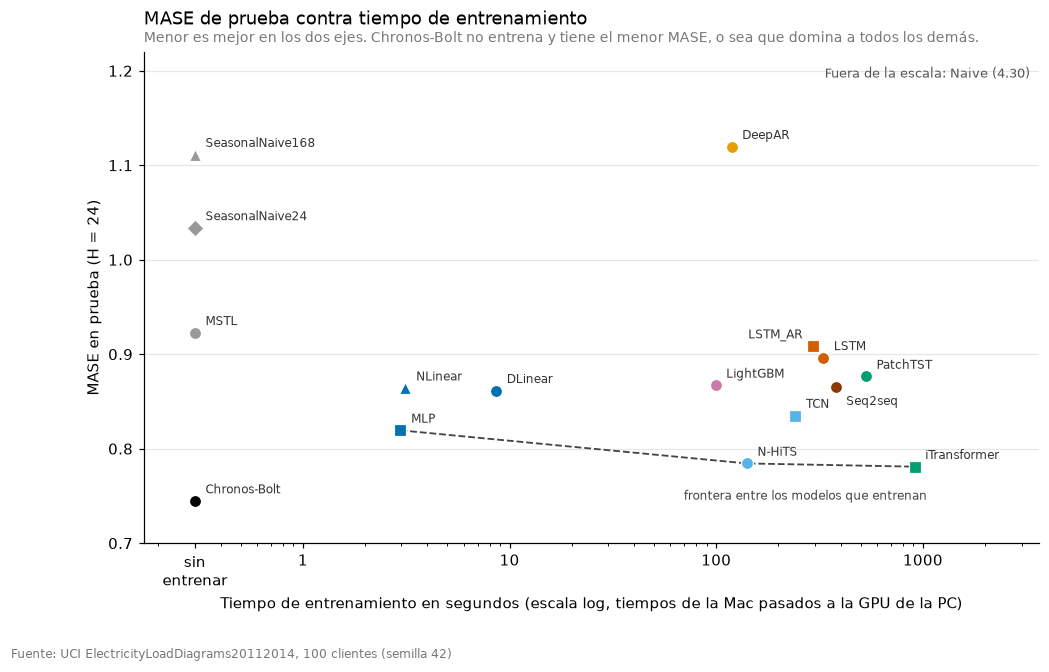

Frontera de Pareto (['Chronos-Bolt'], ['MLP', 'N-HiTS', 'iTransformer'])


In [3]:
f = K.factores_hardware()
print("cociente de tiempo por epoch PC con NVIDIA entre Mac")
for modelo, valor in f.items():
    print(f"  {modelo:8s} {valor:.2f}  ({'la PC es más lenta' if valor > 1 else 'la PC es más rápida'})")

fig, frontera = K.grafica_pareto(tabla)
plt.show()
print("Frontera de Pareto", frontera)

### Gráfica 2. MAE por paso del horizonte

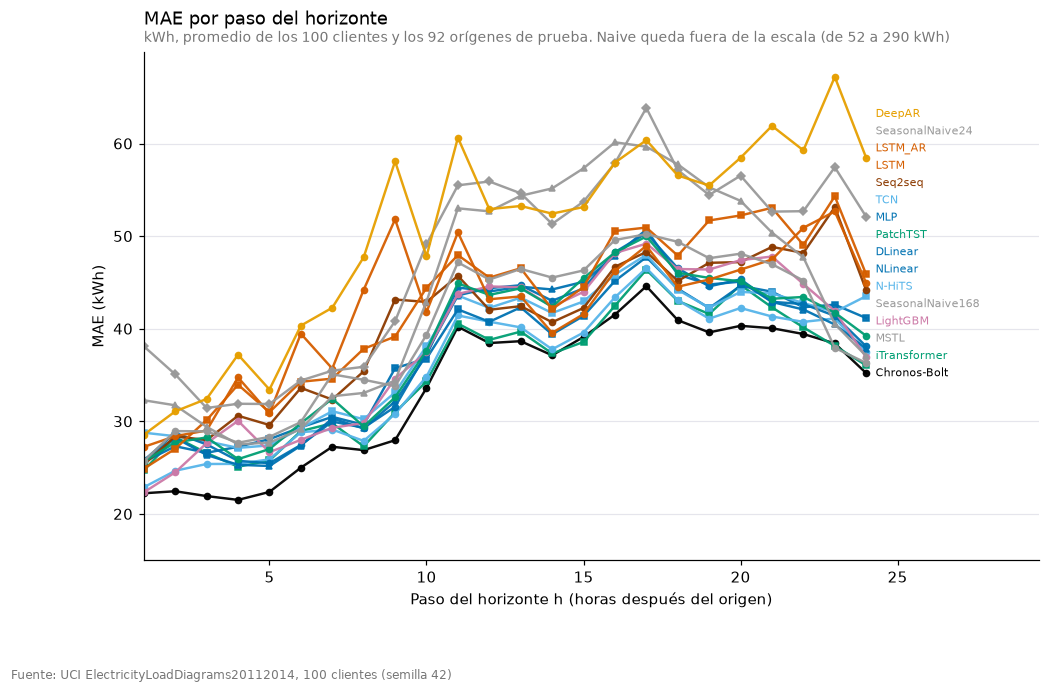

,Modelo,MAE h=1,MAE h=24,Crece,Mejor paso
16,Naive,80.135,52.088,-0.350,24
14,SeasonalNaive168,32.273,37.049,0.148,4
13,SeasonalNaive24,38.101,52.088,0.367,3
12,MSTL,25.693,36.304,0.413,1
1,iTransformer,24.695,36.038,0.459,1
6,NLinear,25.798,37.847,0.467,5
5,DLinear,25.770,38.088,0.478,5
4,TCN,28.773,43.519,0.513,4
9,PatchTST,25.649,39.228,0.529,1
0,Chronos-Bolt,22.229,35.199,0.583,4


In [4]:
fig = K.grafica_error_por_h(tabla)
plt.show()
crec = pd.DataFrame({"Modelo": tabla.Modelo,
                     "MAE h=1": tabla.mae_por_h.map(lambda v: v[0]),
                     "MAE h=24": tabla.mae_por_h.map(lambda v: v[-1]),
                     "Crece": tabla.mae_por_h.map(lambda v: v[-1] / v[0] - 1),
                     "Mejor paso": tabla.mae_por_h.map(lambda v: int(np.argmin(v)) + 1)})
crec.round(3).sort_values("Crece")

### Gráfica 3. MASE contra meses de historia de entrenamiento

Los modelos se entrenaron con 3, 12 y 30 meses de historia, siempre terminando el 2014-06-30, y se midieron en el bloque de validación para no gastar la prueba. El seasonal naive no aprende nada, entonces su línea es plana. Chronos no entrena, y su MASE de validación va como línea horizontal de referencia.

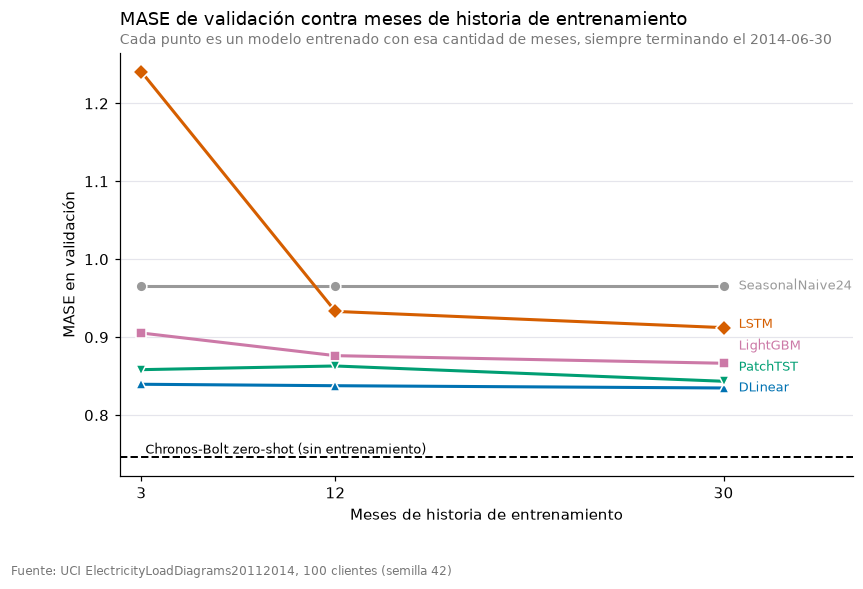

modelo,Chronos,DLinear,LSTM,LightGBM,PatchTST,SeasonalNaive24
meses,,,,,,
0,0.7465,NaN,NaN,NaN,NaN,NaN
3,NaN,0.8396,1.2406,0.9053,0.8583,0.9662
12,NaN,0.8377,0.9330,0.8763,0.8630,0.9662
30,NaN,0.8348,0.9122,0.8665,0.8434,0.9662


In [5]:
fig, hist = K.grafica_historia()
plt.show()
hist.pivot(index="meses", columns="modelo", values="MASE_val").round(4)

### Error por hora del día y en la semana de Navidad

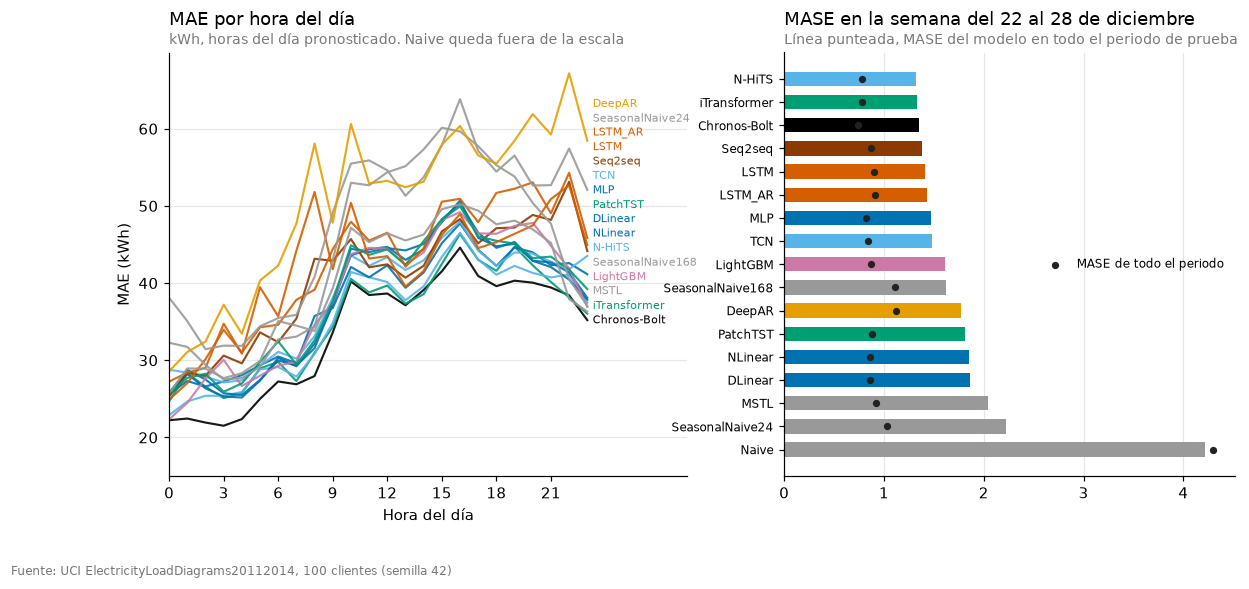

In [6]:
fig = K.grafica_hora_y_navidad(tabla)
plt.show()

En la semana del 22 al 28 de diciembre el error sube en todos los modelos. El MASE de esa semana es entre 1.46 y 2.21 veces el MASE de todo el periodo de prueba, en todos los modelos menos el naive simple (0.98 veces, pero parte de un MASE general de 4.30). Los modelos que usan las covariables de calendario tuvieron un salto menor (N-HiTS 1.68 veces, iTransformer 1.70, seq2seq 1.60 y LSTM 1.58) que los que no las usan (DLinear 2.16, NLinear 2.15, PatchTST 2.06, MSTL 2.21 y seasonal naive de 24 horas 2.15). Chronos no usa covariables y quedó en 1.81. El seasonal naive de 168 horas tuvo el salto más chico (1.46 veces), pero parte de un MASE general malo.

El periodo de prueba termina el 31 de diciembre, entonces el 1 de enero no se evalúa y no hay forma de medir el efecto de Año Nuevo.

In [7]:
nav = pd.DataFrame({"MASE": tabla.MASE.to_numpy(), "MASE 22 al 28 dic": tabla.MASE_navidad.to_numpy(),
                    "Covariables": tabla.Covariables.to_numpy()}, index=tabla.Modelo)
nav["Veces"] = nav["MASE 22 al 28 dic"] / nav["MASE"]
nav.sort_values("Veces").round(3)

,MASE,MASE 22 al 28 dic,Covariables,Veces
Modelo,,,,
Naive,4.300,4.214,No,0.980
SeasonalNaive168,1.111,1.624,No,1.462
LSTM_AR,0.909,1.427,Sí,1.571
LSTM,0.896,1.414,Sí,1.578
DeepAR,1.120,1.767,Sí,1.578
Seq2seq,0.866,1.385,Sí,1.600
N-HiTS,0.784,1.319,Sí,1.682
iTransformer,0.781,1.331,Sí,1.705
TCN,0.835,1.485,Sí,1.778


### Pronóstico probabilístico

Chronos-Bolt y DeepAR entregan los cuantiles P10, P50 y P90. La pinball loss es el promedio de los tres cuantiles, en kWh, y la cobertura es la fracción de valores reales que cae entre el P10 y el P90.

In [8]:
prob = tabla[tabla.Pinball.notna()][["Modelo", "MASE", "Pinball", "Cobertura"]].copy()
prob["Cobertura esperada"] = 0.8
prob.round(4)

,Modelo,MASE,Pinball,Cobertura,Cobertura esperada
0,Chronos-Bolt,0.7446,11.6010,0.8001,0.8
15,DeepAR,1.1197,17.4337,0.7215,0.8


### Reentrenamiento mensual y semillas

Reentrenamiento mensual del mejor modelo de deep learning de librería (N-HiTS), del mejor baseline (MSTL, que ya se reajusta en cada origen), de LightGBM y del MLP de los modelos propios, y semillas de los mejores modelos de deep learning.

In [9]:
display(K.tabla_reentreno().round(4))
for ruta in sorted(R.glob("semillas*.json")):
    s = json.loads(ruta.read_text(encoding="utf-8"))
    print(f"{s['modelo']:8s} MASE de prueba con 3 semillas {[round(c['MASE_prueba'], 4) for c in s['corridas']]}  media {s['MASE_prueba_media']:.4f}  desviación {s['MASE_prueba_desv']:.4f}")

,Modelo,MASE fijo,MASE reentreno mensual,MAE fijo,MAE reentreno mensual,MASE Navidad fijo,MASE Navidad reentreno
0,LightGBM,0.8670,0.8665,38.2738,38.0287,1.6085,1.6377
1,MSTL,0.9228,0.9228,39.7577,39.7577,2.0398,2.0398
2,MLP,0.8194,0.8280,37.3688,37.7750,1.4664,1.4410
3,N-HiTS,0.7844,0.7825,35.5109,35.2636,1.3193,1.3281


MLP      MASE de prueba con 3 semillas [0.8194, 0.8098, 0.8249]  media 0.8181  desviación 0.0077
N-HiTS   MASE de prueba con 3 semillas [0.7844, 0.784, 0.8131]  media 0.7938  desviación 0.0167


### Archivo con los pronósticos de prueba

Se junta el pronóstico de cada modelo en un solo archivo con `unique_id`, `ds`, `modelo` y `y_hat`, como pide el enunciado. El CSV sin comprimir pesa más de 200 MB y GitHub no deja subir archivos de más de 100 MB, entonces se guarda comprimido como `pronosticos_prueba.csv.gz` y `pd.read_csv` lo lee directo. Los parquet de `Resultados/pronosticos/` tienen además el origen, el paso h, el valor real y los cuantiles.

In [10]:
pp = K.pronosticos_prueba()
pp.to_csv(R / "pronosticos_prueba.csv.gz", index=False, float_format="%.3f", compression="gzip")
print(pp.shape, "filas", pp.modelo.nunique(), "modelos")
print(pp.groupby("modelo").size().unique(), "filas por modelo (100 clientes x 92 orígenes x 24 horas =", 100 * 92 * 24, ")")
pp.head(3)

(3753600, 4) filas 17 modelos
[220800] filas por modelo (100 clientes x 92 orígenes x 24 horas = 220800 )


,unique_id,ds,modelo,y_hat
0,MT_013,2014-10-01 00:00:00,Chronos-Bolt,51.590088
1,MT_013,2014-10-01 01:00:00,Chronos-Bolt,53.069069
2,MT_013,2014-10-01 02:00:00,Chronos-Bolt,49.451893


## 8. Discusión y análisis

### ¿Qué modelo ganó y por cuánto superó al seasonal naive? ¿La mejora justifica su costo?

El mejor MASE de prueba fue el de Chronos-Bolt sin entrenar, con 0.7446. Es 28.0% mejor que el seasonal naive de 24 horas (1.0337). Entre los modelos entrenados el mejor por validación fue N-HiTS, con 0.7844 en prueba, o sea 24.1% mejor que el seasonal naive. En kWh el MAE bajó de 47.49 a 35.51 por hora y por cliente (25% menos) y el WAPE de 8.42% a 6.29%. iTransformer quedó igual en prueba (0.7810), pero con 6.5 millones de parámetros y 911 segundos de entrenamiento.

La mejora sí justifica el costo. N-HiTS entrena en 141 segundos en una GPU de consumo y sus 92 pronósticos tardan 28 segundos, que es poco para un pronóstico diario de 100 clientes. En mantenimiento tampoco pide mucho, porque reentrenar cada mes no lo mejoró (0.7844 contra 0.7825), entonces alcanza con entrenarlo una vez y vigilar el error. Frente a MSTL (0.9228) el modelo también gana, y MSTL ya cuesta 503 segundos de inferencia porque se reajusta en cada origen.

### ¿Se replica el hallazgo de DLinear de que un modelo lineal compite con los Transformers? ¿En qué horizonte?

Se replica a medias. DLinear (16 mil parámetros y 17.5 segundos de entrenamiento) quedó en 0.8614, mejor que PatchTST (0.8764, 534 mil parámetros y 529 segundos) y casi igual que LightGBM (0.8670). Le ganó a PatchTST en 15 de los 24 pasos del horizonte, sobre todo entre h = 3 y h = 11 y en cinco de los últimos seis pasos. Pero iTransformer, que también es un Transformer, fue 9.3% mejor que DLinear y le ganó en 22 de los 24 pasos (DLinear solo gana en h = 5 y h = 6), y lo mismo pasa con N-HiTS. Con TCN quedaron parejos, porque DLinear le gana en 13 de los 24 pasos aunque TCN termina con mejor MASE de prueba (0.8351). Entonces depende del Transformer. PatchTST no usa covariables de calendario ni terminó de entrenar (usó los 3,000 pasos), y esas dos cosas pudieron perjudicarlo.

### ¿Qué estrategia multi-paso funcionó mejor y cómo crece el error con el horizonte?

Con la LSTM la mejor fue el encoder-decoder (seq2seq, MASE 0.8657), después la multi-salida (0.8962) y al final la autorregresiva (0.9087). La autorregresiva es mejor que la multi-salida en 8 de los primeros 11 pasos (24.9 kWh contra 27.2 en h = 1) y después casi nunca, porque solo gana en h = 22, y termina peor (45.9 contra 44.9 en h = 24). Eso es la acumulación de errores de usar las propias predicciones. En el seq2seq el mejor teacher forcing fue 0 (MASE de validación 0.8876), mejor que 0.5 (0.9919) y que 1 (0.9185). Los modelos recursivos de otras familias muestran lo mismo. LightGBM tiene uno de los errores más bajos en h = 1 (22.3 kWh, igual que Chronos con 22.2) pero el cociente entre h = 24 y h = 1 es 1.65, mayor que el de los modelos directos como iTransformer (1.46) y DLinear (1.48). DeepAR llega a 2.05.

Hay que tener cuidado al leer el error por paso. Como todos los orígenes son a las 00:00, el paso h es también la hora del día, y el consumo en la tarde es más alto que de madrugada. Por eso el MAE sube y baja con el ciclo diario además de crecer con el horizonte, y la comparación entre estrategias es más confiable en el mismo paso que entre pasos.

### ¿Qué efecto tuvieron la ventana L, la normalización y la cantidad de historia? ¿Desde cuántos meses el deep learning supera a LightGBM y a los estadísticos?

La ventana ayudó hasta 168 horas y después casi nada, salvo en los modelos lineales. En DLinear el MASE de validación fue 0.9200 con L = 48, 0.8528 con 168 y 0.8404 con 336, y en PatchTST fue 0.9187, 0.8484 y 0.8434. La LSTM no mejoró con L = 336 (0.9917 contra 0.9706).

La normalización sí importó. Con una sola media y desviación para todo el panel el MASE de validación de DLinear subió de 0.8528 a 1.0072 y el de la LSTM de 0.9706 a 2.2185. El z-score por cliente fue indispensable. RevIN agregó poco, porque en DLinear dio lo mismo (0.8533) y en el MLP bajó de 0.8192 a 0.8041 (1.8%).

Con la historia, DLinear con solo 3 meses (0.8396) ya supera a LightGBM con 3 meses (0.9053), a MSTL (0.9013) y al seasonal naive (0.9662), todo en validación, y PatchTST con 3 meses (0.8583) también. La LSTM necesita más datos, porque con 3 meses (1.2406) es peor que el seasonal naive, MSTL y LightGBM, con 12 meses (0.9330) supera al seasonal naive pero no a MSTL ni a LightGBM (0.8763), y con 30 meses (0.9122) sigue detrás de LightGBM (0.8665). Chronos no depende de la historia de entrenamiento y tiene 0.7465 en validación.

### ¿Convino un modelo global o uno por cliente? ¿Qué clientes se benefician más del global?

Convino el global, con poca diferencia. En los 10 clientes del experimento el MASE fue 0.8141 con el modelo global y 0.8239 con los 10 modelos locales, o sea 1.2% a favor del global. El global fue mejor en 6 de los 10 clientes. Los que más ganaron fueron MT_363 (0.084 de MASE), MT_359 (0.071) y MT_267 (0.044). Los que prefirieron el local fueron MT_279 (el global fue 0.139 peor), MT_097, MT_050 y MT_046. No se analizó por qué esos clientes cambian.

### ¿Qué tan cerca quedó Chronos zero-shot de los modelos entrenados? ¿Cuándo usarlo?

Quedó por delante de todos. Su MASE de prueba (0.7446) es 5.1% mejor que el de N-HiTS, con intervalos bien calibrados (cobertura de 80.0% para un intervalo de 80%). Hay que tomar el resultado con cuidado, porque el paper de Chronos incluye un conjunto de electricidad de 370 hogares y no se pudo confirmar si estos datos estuvieron en el entrenamiento previo. Si estuvieron, la ventaja sería menor.

Lo usaría cuando no hay tiempo, datos o GPU para entrenar, por ejemplo con clientes nuevos que tienen pocas semanas de historia, o como primera referencia antes de gastar en una red propia. También cuando se necesitan intervalos de confianza. Entrenaría una red cuando el costo de inferencia importe (Chronos tiene 205 millones de parámetros y tardó 49 segundos contra 28 de N-HiTS en los 92 orígenes) o cuando se quiera usar covariables, que Chronos no recibe.

### ¿Qué pasó en Navidad? ¿Ayudaron las covariables de feriado?

El error subió en casi todos los modelos, entre 1.46 y 2.21 veces el MASE normal, y ninguno bajó de 1.31 en esa semana. En general los modelos con calendario tuvieron un salto menor que los que no lo usan, y los tres mejores de la semana (N-HiTS 1.319, iTransformer 1.331 y Chronos 1.348) quedaron cerca. Entonces las covariables ayudaron algo, pero no resolvieron el problema, y el cambio de régimen afectó a todos. Es lógico porque la covariable de feriado solo marca el 25 de diciembre, y los días vecinos (24, 26 y 27) también se comportan distinto y no tienen marca.

### ¿Qué tan sensibles fueron los resultados a la semilla?

Con 3 semillas, N-HiTS tuvo un MASE de prueba medio de 0.7938 y una desviación estándar de 0.0167 (0.7844, 0.7840 y 0.8131). El MLP de los modelos propios tuvo 0.8181 con desviación de 0.0077. La desviación de N-HiTS es mayor que la diferencia con iTransformer, entonces esos dos modelos no se pueden ordenar con estos datos.